In [6]:
import utils.param_loader as param_loader
import numpy as np

from utils.sensitivity_analysis import (
    compute_local_sensitivity,
    compute_sobol_sensitivity,
    plot_local_sensitivity,
    plot_sobol_sensitivity,
    plot_sobol_sensitivity_thesis
)

In [7]:
params = param_loader.load_parameters()

In [8]:
evolving_traits = [
    "g_bs",
    "g_m",
    "v_pmax",
    "v_cmax_mes",
    "v_cmax_bs",
    "k_c",
    "k_o",
    "k_p",
    "u_a",
    "k_l"
]

bounds = [
    [0.0001, 0.1],  # g_bs
    [1, 6], # g_m
    [0.1, 200],  # v_pmax
    [0.1, 200],  # v_cmax_mes
    [0.1, 200],  # v_cmax_bs
    [10000.0, 100000.0],  # k_c
    [7500000.0, 27500000.0],  # k_o
    [1000.0, 70000.0],  # k_p
    [1, 500],  # u_a
    [0.005e-6, 0.005e-5],  # k_l
]


# Run local sensitivity
local_scores = compute_local_sensitivity(
    evolving_traits=evolving_traits,
    bounds=bounds,
    params=params,
    epsilon=0.5  # Adjust epsilon as needed
)


[INFO] Running Local Sensitivity Analysis...


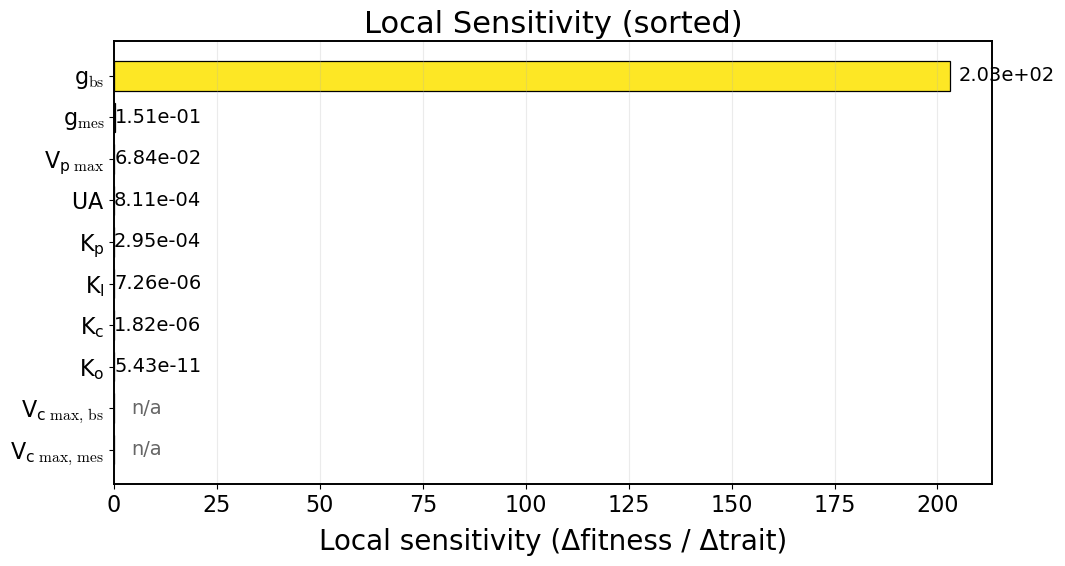

In [9]:
plot_local_sensitivity(local_scores, evolving_traits, trait_names=[
        "$g_{\\text{bs}}$",
        "$g_{\\text{mes}}$",
        "$V_{p~\\max}$",
        "$V_{c~\\text{max, mes}}$",
        "$V_{c~\\text{max, bs}}$",
        "$K_c$",
        "$K_o$",
        "$K_p$",
        "$UA$",
        "$K_l$"
    ],
    save_path="plots/sensitivity/local_sensitivity.png")

In [10]:
# Run global sensitivity (Sobol)
sobol_result = compute_sobol_sensitivity(
    evolving_traits=evolving_traits,
    bounds=bounds,
    params=params,
    n_samples=2**16,  # Adjust as needed; higher = more accurate
    n_jobs=-1,
)


[INFO] Running Global (Sobol) Sensitivity Analysis...


[INFO] Evaluating Sobol samples:   0%|          | 32/1441792 [00:00<4:53:51, 81.77it/s]


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public Lic

[INFO] Evaluating Sobol samples:   0%|          | 64/1441792 [00:00<4:32:51, 88.06it/s]


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public Lic

[INFO] Evaluating Sobol samples:   0%|          | 80/1441792 [00:00<4:02:16, 99.18it/s]

... (44 outputs left out)

[WARN] Sobol evaluation failed for x=[0.09582555923461915, 4.805198669433594, 134.2141227722168, 128.75725784301758, 21.093221282958986, 89419.47937011719, 18118133.544921875, 61051.246643066406, 190.83182525634766, 3.7917442321777344e-08] with error: Error in Opti::solve [OptiNode] at .../casadi/core/optistack.cpp:157:
.../casadi/core/optistack_internal.cpp:998: Assertion "return_success(accept_limit)" failed:
Solver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'


[INFO] Evaluating Sobol samples: 100%|██████████| 1441792/1441792 [8:21:31<00:00, 47.91it/s] 


[INFO] Sobol run completed: 1441764 succeeded, 28 failed of 1441792.
[INFO] 28 NaN outputs detected. Replacing with mean of valid results.


/home/foko.kuate/miniconda3/envs/casadi/lib/python3.12/site-packages/SALib/util/__init__.py:274: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  names = list(pd.unique(groups))


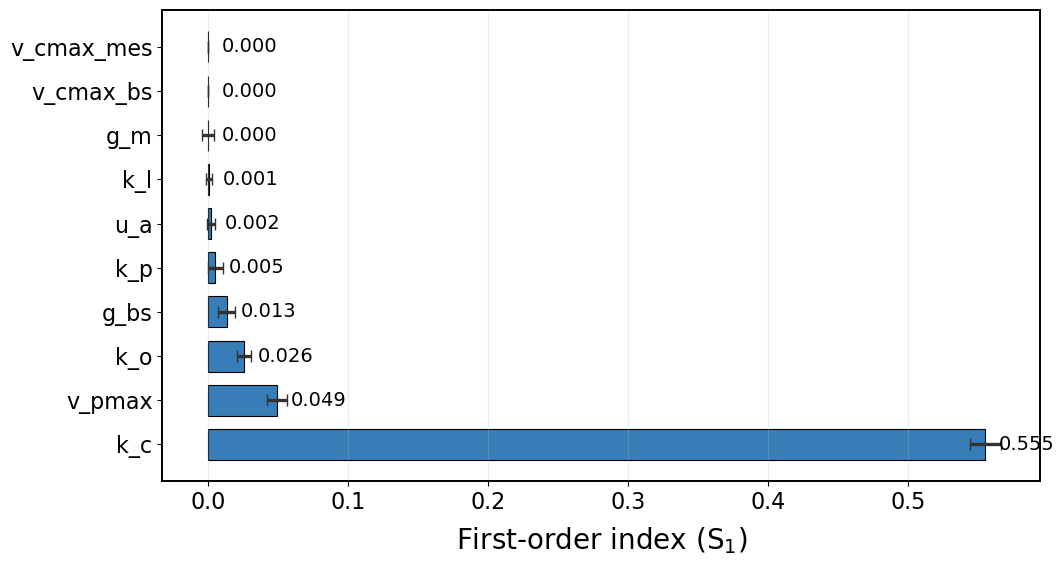

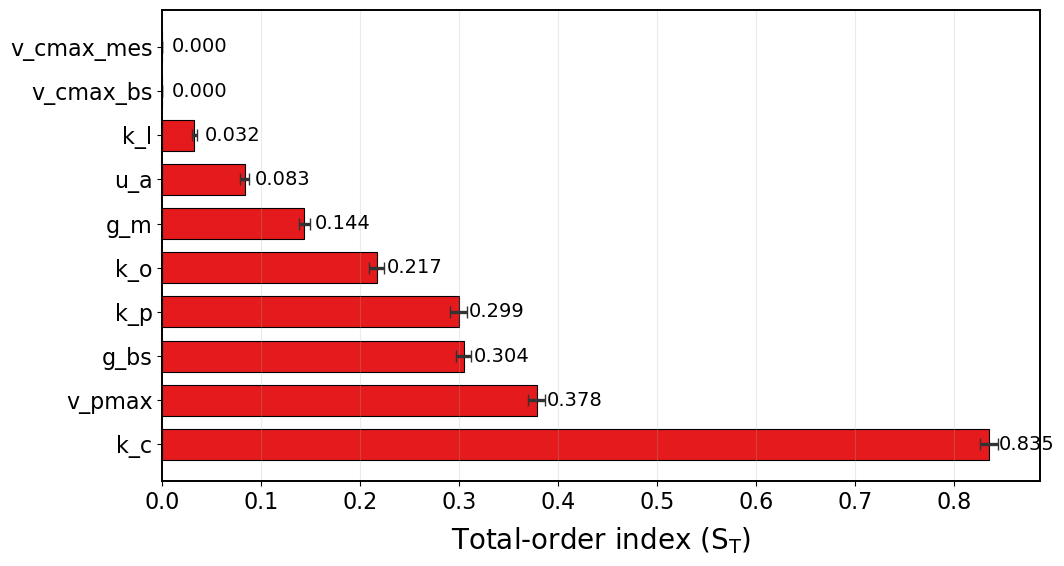

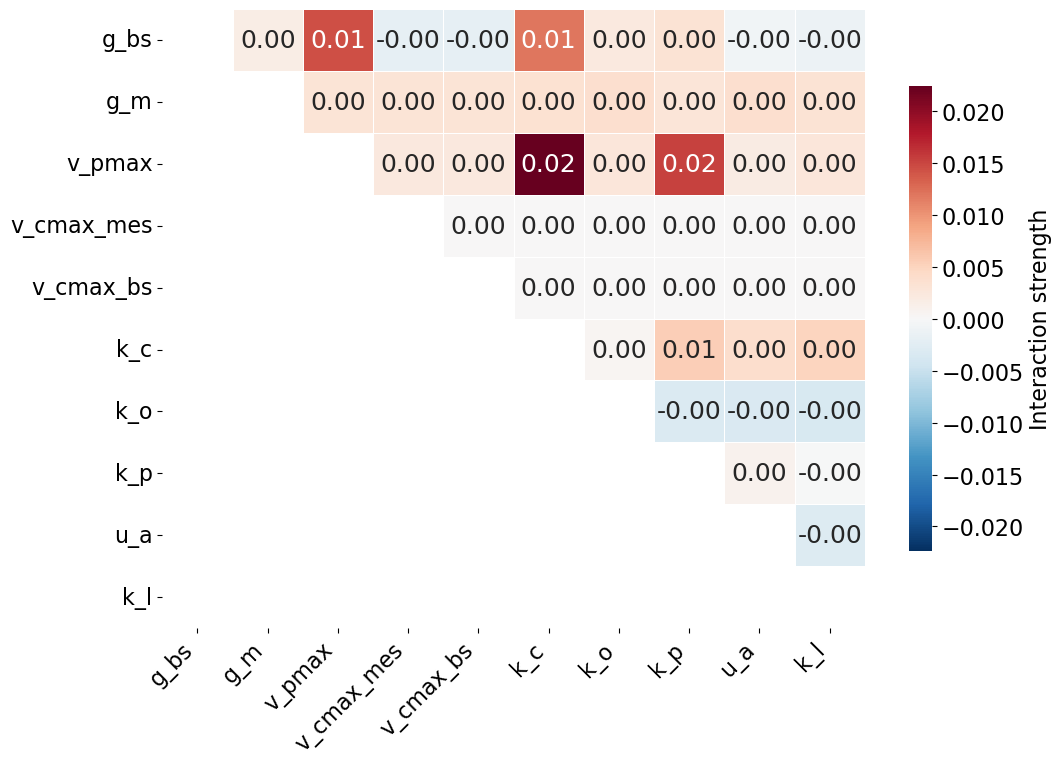

In [11]:
plot_sobol_sensitivity(sobol_result, evolving_traits)

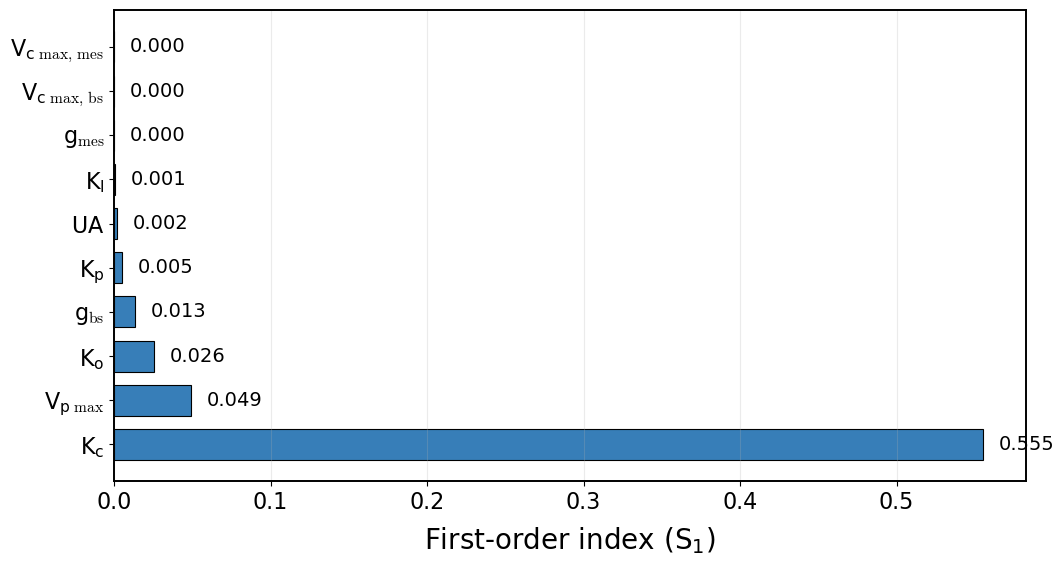

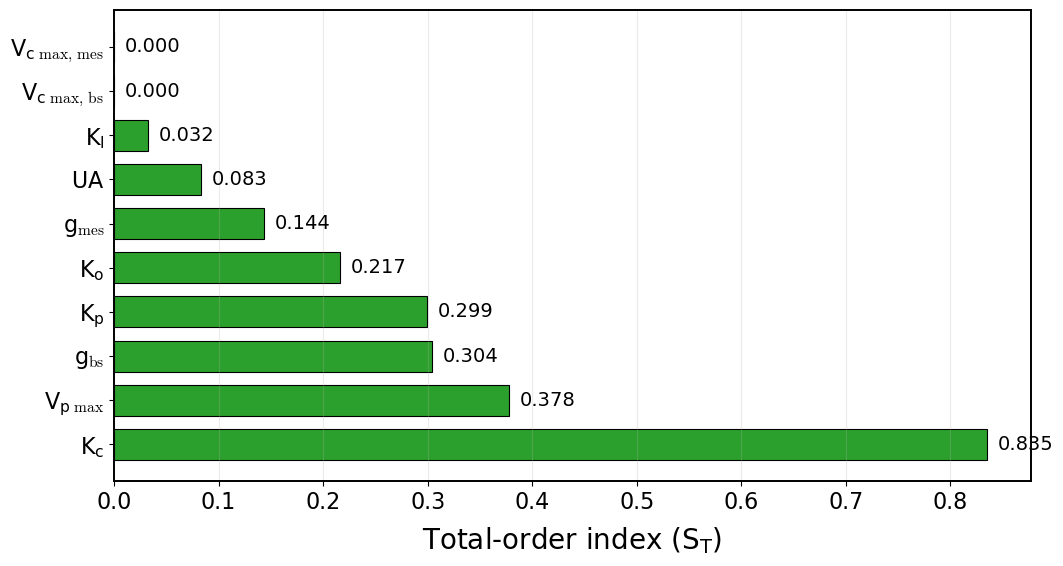

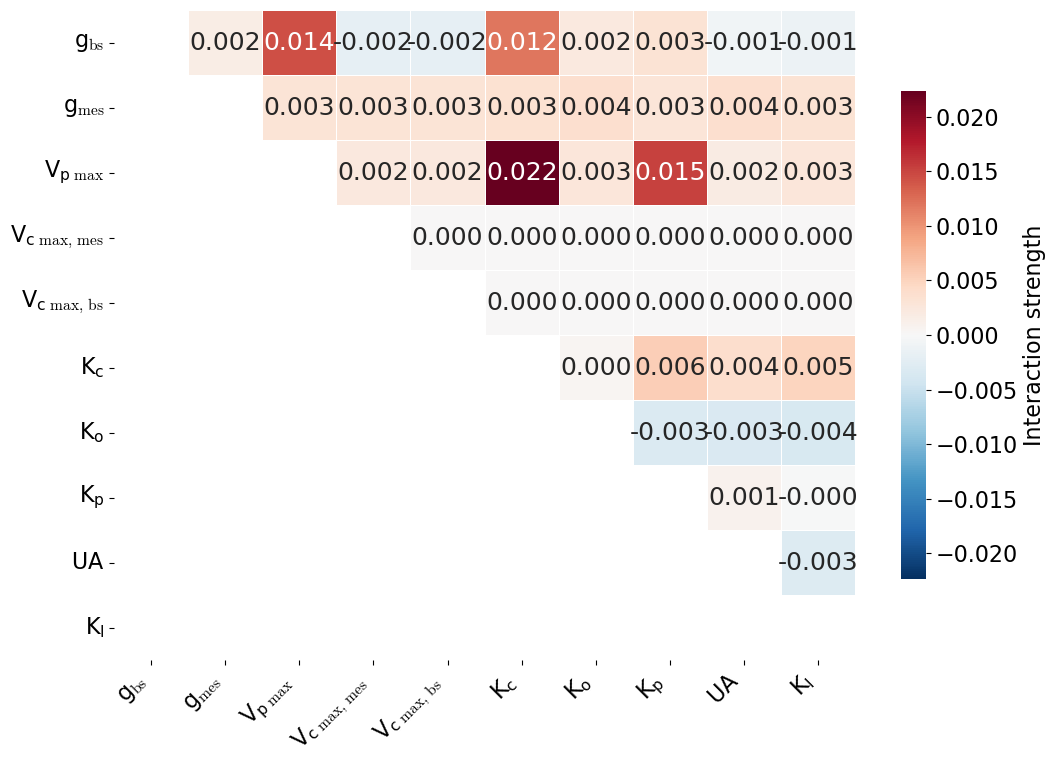

In [12]:
plot_sobol_sensitivity_thesis(
    sobol_result,
    evolving_traits,
    trait_names=[
        "$g_{\\text{bs}}$",
        "$g_{\\text{mes}}$",
        "$V_{p~\\max}$",
        "$V_{c~\\text{max, mes}}$",
        "$V_{c~\\text{max, bs}}$",
        "$K_c$",
        "$K_o$",
        "$K_p$",
        "$UA$",
        "$K_l$"
    ],
    save_path="plots/sensitivity/sobol_17.png"
)